# Isochrons 02. One hundred FitzHugh-Nagumo isochrons by continuation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/isochrons/02_FHN_isochrons-by-continuation.ipynb)

Notebook 01 drew isochrons by brute force: the asymptotic phase of every grid point,
measured from spike times, and its contour lines. Here we compute them the way
Osinga & Moehlis (SIAM J. Appl. Dyn. Syst. 9, 2010) do for the reduced
Hodgkin-Huxley neuron, but for FitzHugh-Nagumo: **each isochron is a one-parameter
family of orbit segments, found as solutions of a boundary value problem (BVP) and
followed by continuation in XPPAUT 8.2's AUTO.** Then we check them against the brute
force of notebook 01.

| step | what | XPP / AUTO |
|---|---|---|
| 1 | the model, the orbit Γ, its period T and phase zero γ0 (maximum of v) | Initialconds > Go, Periodic |
| 2 | the isochron's direction n_s at γ(θ), perpendicular to the adjoint | Numerics > Averaging > New adj |
| 3 | the BVP: segments u' = kT F(u) on [0, 1] with u(1) = γ + δ n_s | an .ode file with two `bndry` lines |
| 4 | stage 1: start from Γ (δ = 0), continue in δ until abs(δ) = η | Run > Bdry Value, then continuation |
| 5 | stages k = 2, 3, …: start from the last segment followed by one period of Γ | the paper's concatenation (3.5) |
| 6 | all 100 phases θ_i = i/100, inside and outside Γ | in parallel, one XPPAUT per process |
| 7 | checks: against the brute-force phase, and no crossings | |

Computing all 100 isochrons takes a while (see the Settings). The results are also
stored with the notebook (`data/02_FHN_isochrons.npz`), so by default the notebook
computes the 0-phase isochron live and loads the other 99.

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp tqdm --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.3.0

## Settings

* `COMPUTE_ALL = True` recomputes all 100 isochrons (about 10 s each, so about
  15 core-minutes; with `N_WORKERS` processes it is that many times faster). `False` computes the 0-phase
  isochron and loads the stored results for the rest.
* `KMAX`: stages inside Γ (time-k T maps). `KOUT`: stages outside.

In [2]:
COMPUTE_ALL = False
N_WORKERS = 4                     # processes for COMPUTE_ALL (each runs its own XPPAUT)
KMAX, KOUT = 3, 1
NPHASE = 100
STORED = "data/02_FHN_isochrons.npz"
STORED_URL = "https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/data/02_FHN_isochrons.npz"

In [3]:
import json
import multiprocessing as mp
import os
import tempfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path as Polygon
from pyxpp.builder import ModelBuilder
from tqdm.auto import tqdm

WORK = Path(tempfile.mkdtemp())
plt.rcParams.update({"figure.dpi": 100})

## 1. The model, the orbit Γ, the period T and phase zero

$$\dot v = v - \frac{v^3}{3} - w + I,\qquad \dot w = \varepsilon\,(v + a - b w),\qquad
I = 0.5,\ a = 0.7,\ b = 0.8,\ \varepsilon = 0.08 .$$

Phase zero γ0 is the point of Γ where v is largest (there v' = 0), found by bisection on
the time, as in the paper.

In [4]:
FV = "v-v^3/3-w+i"
FW = "eps*(v+a-b*w)"
PARS = dict(i=0.5, a=0.7, b=0.8, eps=0.08)
OPTS = dict(meth="rk4", bound=1e4, jac_eps=1e-7, newt_tol=1e-10)

mb = (ModelBuilder("fhn").ode("v", FV).ode("w", FW).parameter(**PARS).initial(v=-1, w=1)
      .option(total=400, dt=0.01, maxstor=400000, **OPTS))
print(mb.render())
m = mb.load(WORK / "fhn.ode")
m.run()                                            # XPP: Initialconds > Go
m.buttons.xi_vs_t("v")
m.buttons.initialconds.periodic()                  # XPP: Initialconds > Periodic -> total = T
T = m.numerics["total"]


def flow(x, t, dt=1e-3):
    """Phi(t, x) by XPP (RK4 with a step of at most dt that divides t)"""
    m.set(v=x[0], w=x[1])
    m.run(keep=False, total=t, dt=t / max(1, int(np.ceil(t / dt))), trans=0)
    s = m.last_state()
    return np.array([s["V"], s["W"]])


g = flow(np.array([m.ics["V"], m.ics["W"]]), T - 0.5)
a, b = 0.0, 1.0
for _ in range(45):                                # bisection for v' = 0 at the top of the spike
    c = 0.5 * (a + b)
    a, b = (c, b) if m.rhs(flow(g, c))["V"] > 0 else (a, c)
gamma0 = flow(g, 0.5 * (a + b))
m.set(v=gamma0[0], w=gamma0[1])
orb = m.run(keep=False, total=T, dt=0.001, trans=0)
POLY = np.c_[orb["v"], orb["w"]]
eq = m.equilibrium({"v": -0.8, "w": -0.1})
xstar = np.array([eq.x["V"], eq.x["W"]])
# Floquet multiplier from Liouville's formula: mu = exp( integral of div F ), div F = 1 - v^2 - eps*b
divF = 1 - orb["v"] ** 2 - PARS["eps"] * PARS["b"]
mu_log = float(np.trapezoid(divF, orb.t))
print(f"T = {T:.6f}; gamma0 = ({gamma0[0]:.6f}, {gamma0[1]:.6f}); x* = ({xstar[0]:.4f}, {xstar[1]:.4f})")
print(f"integral of div F over one period = {mu_log:.4f}, so the multiplier mu = {np.exp(mu_log):.3e}")

v'=v-v^3/3-w+i
w'=eps*(v+a-b*w)
par i=0.5,a=0.7,b=0.8,eps=0.08
init v=-1,w=1
@ total=400,dt=0.01,maxstor=400000,meth=rungekutta,bound=10000.0,jac_eps=1e-07,newt_tol=1e-10
done



T = 39.474415; gamma0 = (1.852117, 0.234320); x* = (-0.8048, -0.1311)
integral of div F over one period = -38.3102, so the multiplier mu = 2.302e-17


The multiplier is tiny: μ ≈ e^(−38) ≈ 2 × 10⁻¹⁷. FitzHugh-Nagumo with ε = 0.08 is a
relaxation oscillator too, and one period squeezes the isochron's direction almost as
strongly as in the reduced Hodgkin-Huxley model (μ ≈ 10⁻²⁰). That is exactly why the
paper's continuation is needed instead of backward integration.

## 2. The direction n_s of the isochron at γ(θ)

XPP's adjoint Z(t) is the gradient of the asymptotic phase along Γ; the isochron is
perpendicular to it: n_s = (Z_w, −Z_v)/|Z|, oriented to point out of Γ.

In [5]:
A = m.buttons.numerics.averaging                   # XPP: Numerics > Averaging > New adj
A.parameters(6400)
A.new_adj()
adj = m.data


def phase_point(theta):
    gth = gamma0.copy() if theta == 0 else flow(gamma0, theta * T)
    zv, zw = np.interp(theta * T, adj.t, adj["v"]), np.interp(theta * T, adj.t, adj["w"])
    ns = np.array([zw, -zv]) / np.hypot(zv, zw)
    f = m.rhs(gth)
    if f["V"] * ns[1] - f["W"] * ns[0] > 0:        # make n_s point out of Gamma
        ns = -ns
    return gth, ns


print("theta = 0: n_s =", phase_point(0.0)[1])

theta = 0: n_s = [ 0.99937326 -0.03539896]


## 3. The boundary value problem, as an XPP .ode file

Orbit segments of length per = kT, with time rescaled to [0, 1], that end on the short
straight piece L_η = {γ + δ n_s, |δ| ≤ η} of the isochron. `v'` in a `bndry` line means
v at the right end. u(0) is free, so continuation in d = δ gives a one-parameter family,
and **the start point u(0) of every member is a point of the isochron** (it reaches the
isochron's linear piece after exactly k periods).

In [6]:
ETA, DS = 1e-4, 1e-5                               # the paper's eta and DS = 0.1 eta
NTST_GAMMA = 100                                   # mesh intervals per period; stage k uses 100 k
AUTO_NUM = dict(ncol=4, dsmin=1e-8, dsmax=0.1, epsl=1e-8, epsu=1e-8, epss=1e-6,
                itmx=8, itnw=5, nwtn=3, iad=3, normmax=1e6, npr=100000)
NMX = 5000
WINDOW = (-3.0, 3.0, -1.5, 2.5)                    # the outside branch is followed until it leaves this


def bvp_builder():
    bb = ModelBuilder("fhn_isochron_bvp")
    bb.comment("orbit segments u' = per*F(u) on [0,1] that end on L_eta(gamma): u(1) = gamma + d*n_s")
    return (bb.ode("v", f"per*({FV})").ode("w", f"per*({FW})")
            .parameter(**PARS).parameter(per=T, gv=0, gw=0, tv=1, tw=0, d=0)
            .boundary("v'-gv-d*tv").boundary("w'-gw-d*tw")
            .option(total=1, dt=1e-4, maxstor=400000, **OPTS))


g0, ns0 = phase_point(0.0)
print(bvp_builder().render().replace("gv=0,gw=0,tv=1,tw=0,d=0",
                                     f"gv={g0[0]:.10g},gw={g0[1]:.10g},tv={ns0[0]:.10g},tw={ns0[1]:.10g},d=0"))


def load_bvp():
    B = bvp_builder().load(Path(tempfile.mkdtemp()) / "fhn_isochron_bvp.ode")
    B.auto.parameters("d", "per")
    return B

# orbit segments u' = per*F(u) on [0,1] that end on L_eta(gamma): u(1) = gamma + d*n_s
v'=per*(v-v^3/3-w+i)
w'=per*(eps*(v+a-b*w))
par i=0.5,a=0.7,b=0.8,eps=0.08
par per=39.474414980216245,gv=1.852117473,gw=0.2343204565,tv=0.9993732605,tw=-0.03539895695,d=0
bndry v'-gv-d*tv
bndry w'-gw-d*tw
@ total=1,dt=0.0001,maxstor=400000,meth=rungekutta,bound=10000.0,jac_eps=1e-07,newt_tol=1e-10
done



## 4–5. Algorithm Isochron

* **Start a stage** (AUTO: *Run > Bdry Value* from a given solution). Stage 1 starts from
  Γ itself (δ = 0). XPP's AUTO puts the starting solution on a uniform mesh, so a few
  steps with δ unbounded let the mesh adapt before the real continuation.
* **Choose the direction** by probing a few steps each way: inside or outside Γ at stage
  1; at stage k > 1, the way that extends the isochron (the other way goes back over the
  previous stage).
* **Continue in δ** until |δ| = η. Every point's u(0) is an isochron point.
* **Next stage**: the last segment (k−1 periods) followed by one period of Γ, rescaled to
  [0, 1] (the paper's eq. 3.5), with per = kT and NTST = 100k.

In [7]:
class Isochron:
    def __init__(self, B, gth, ns):
        self.B, self.g, self.ns = B, gth, ns
        self.poly = Polygon(POLY)
        self.log = []
        B.set(per=T, v=gth[0], w=gth[1], d=0)      # stage 1 starts from Gamma, from gamma, over one period
        tr = B.run(total=1, dt=1e-4)
        self.uG = np.asarray(tr.t, float), np.c_[tr["v"], tr["w"]].astype(float)

    @staticmethod
    def pts(points):
        return np.array([[p.u0["v"], p.u0["w"], p.par["d"]] for p in points]).reshape(-1, 3)

    def start(self, k, initial):
        for ntst, itnw in [(NTST_GAMMA * k, 5), (NTST_GAMMA * k, 20), (2 * NTST_GAMMA * k, 20),
                           (4 * NTST_GAMMA * k, 20)]:
            self.B.set(per=k * T, gv=self.g[0], gw=self.g[1], tv=self.ns[0], tw=self.ns[1], d=0)
            self.B.auto.reset()
            first = self.B.auto.run("d", start="bdry value", initial=initial, ntst=ntst, ds=DS, nmax=6,
                                    parmin=-1, parmax=1, **dict(AUTO_NUM, itnw=itnw, dsmax=1e-6))
            if len(first) == 6 and all(p.type != "MX" for p in first) and abs(first[-1].par["d"]) < ETA / 10:
                return first[-1], ntst, itnw
            self.log.append(f"k={k}: start with NTST={ntst}, ITNW={itnw} failed")
        raise RuntimeError(f"k={k}: AUTO did not converge from the starting solution")

    def delta_back(self, sol, k):
        """delta' = (u((k-1)/k) - gamma) . n_s: where the segment is one period before its end"""
        t, U = sol
        tt = (k - 1) / k
        j = int(np.clip(np.searchsorted(t, tt) - 2, 0, len(t) - 4))
        ts, Us = t[j:j + 4], U[j:j + 4]
        w = np.array([np.prod([(tt - ts[q]) / (ts[l] - ts[q]) for q in range(4) if q != l]) for l in range(4)])
        return float((w @ Us - self.g) @ self.ns)

    def score(self, u, k, direction, probe, d0):
        if k == 1:                                  # stage 1: does the probe go inside (or outside) Gamma?
            last = u[-max(3, len(u) // 4):, :2]
            far = last[np.hypot(*(last - self.g).T) > 1e-2]
            return 0.0 if len(far) == 0 else (self.poly.contains_points(far).mean() - 0.5) * (-direction)
        d1 = self.delta_back(probe[-1].solution, k)  # stage k > 1: does |delta'| grow (extend)?
        return (abs(d1) - abs(d0)) / abs(d0)

    def stage(self, k, direction, initial, nprobe=25):
        B, t0 = self.B, time.time()
        p0, ntst, itnw = self.start(k, initial)
        d0 = self.delta_back(p0.solution, k) if k > 1 else None
        scores = {}
        for n_try in (nprobe, 6 * nprobe):
            for sign in (1, -1):
                probe = B.auto.run(grab=p0.label, ds=sign * DS, nmax=n_try, parmin=-ETA, parmax=ETA, **AUTO_NUM)
                u = self.pts(probe)
                scores[sign] = self.score(u, k, direction, probe, d0)
                if scores[sign] > 0.01:
                    break
            else:
                sign = max(scores, key=scores.get)
                if scores[sign] <= 0:
                    continue
                probe = B.auto.run(grab=p0.label, ds=sign * DS, nmax=n_try, parmin=-ETA, parmax=ETA, **AUTO_NUM)
                u = self.pts(probe)
            break
        else:
            raise RuntimeError(f"k={k}: neither direction goes the requested way {scores}")
        parts, last = [u], probe[-1]
        chunk = NMX if direction < 0 else 100
        while abs(last.par["d"]) < ETA and last.type != "MX" and sum(map(len, parts)) < NMX:
            x0, x1, y0, y1 = WINDOW
            if direction > 0 and not (x0 < last.u0["v"] < x1 and y0 < last.u0["w"] < y1):
                break                               # the outside branch has left the window
            more = B.auto.run(grab=last.label, ds=sign * DS, nmax=min(chunk, NMX - sum(map(len, parts))),
                              parmin=-ETA, parmax=ETA, **AUTO_NUM)
            if len(more) <= 1:
                break
            parts.append(self.pts(more)[1:])
            last = more[-1]
        u = np.vstack(parts)
        info = dict(k=k, side="in" if direction < 0 else "out", ntst=ntst, points=len(u),
                    d_end=float(last.par["d"]), seconds=round(time.time() - t0, 1))
        self.log.append(json.dumps(info))
        return u, last.solution, info

    def concatenate(self, k, sol):
        """eq. (3.5): the last segment (k-1 periods) followed by one period of Gamma, on [0, 1]"""
        (ts, Us), (tG, UG) = sol, self.uG
        tt = np.linspace(0, 1, 4000 * k + 1)
        a = tt <= (k - 1) / k
        U = np.empty((len(tt), 2))
        for j in range(2):
            U[a, j] = np.interp(tt[a] * k / (k - 1), ts, Us[:, j])
            U[~a, j] = np.interp(tt[~a] * k - (k - 1), tG, UG[:, j])
        return tt, U

    def run(self, kmax, kout, bar=None):
        res = {}
        for direction, kk in ((-1, kmax), (+1, kout)):
            init = self.uG
            for k in range(1, kk + 1):
                u, sol, info = self.stage(k, direction, init)
                res[(info["side"], k)] = u
                if bar is not None:
                    bar.set_postfix(stage=f"{info['side']} k={k}", points=info["points"], NTST=info["ntst"])
                    bar.update(1)
                if k < kk:
                    init = self.concatenate(k + 1, sol)
        return res

### The 0-phase isochron, live

Stage by stage, printed as it goes.

θ = 0:   0%|          | 0/4 [00:00<?, ?stage/s]

{"k": 1, "side": "in", "ntst": 100, "points": 524, "d_end": -0.00010328219635334217, "seconds": 1.6}
{"k": 2, "side": "in", "ntst": 200, "points": 417, "d_end": -0.00013345515554048602, "seconds": 2.6}
{"k": 3, "side": "in", "ntst": 300, "points": 329, "d_end": -0.000246893871762927, "seconds": 3.2}
{"k": 1, "side": "out", "ntst": 100, "points": 124, "d_end": -1.1019488710444276e-11, "seconds": 0.4}


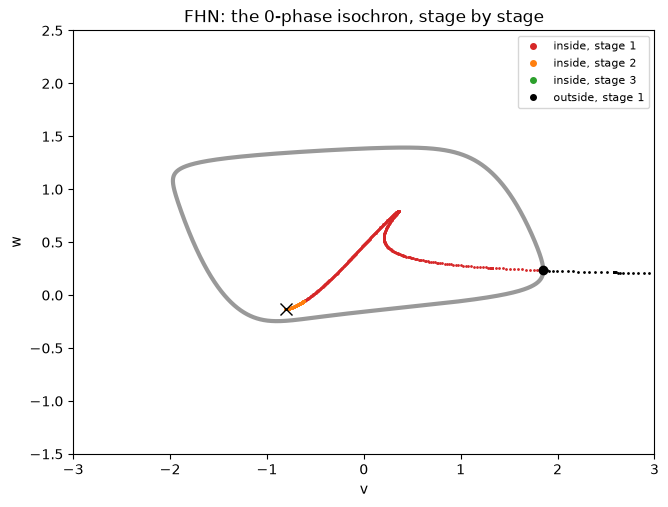

In [8]:
B = load_bvp()
with tqdm(total=KMAX + KOUT, desc="θ = 0", unit="stage") as bar:
    iso0 = Isochron(B, g0, ns0)
    res0 = iso0.run(KMAX, KOUT, bar=bar)
for line in iso0.log:
    print(line)

cols = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(POLY[:, 0], POLY[:, 1], color="0.6", lw=3)
for (side, k), u in res0.items():
    ax.plot(u[:, 0], u[:, 1], ".", ms=2, color=cols[k - 1] if side == "in" else "k",
            label=f"{'inside' if side == 'in' else 'outside'}, stage {k}")
ax.plot(*g0, "ko"); ax.plot(*xstar, "x", color="k", ms=9)
ax.set(xlim=WINDOW[:2], ylim=WINDOW[2:], xlabel="v", ylabel="w", title="FHN: the 0-phase isochron, stage by stage")
ax.legend(fontsize=8, markerscale=4)
plt.show()

## 6. All 100 isochrons

θ_i = i/100. With `COMPUTE_ALL = False` the stored results are loaded (from the
notebook's folder, or downloaded from the repository).

In [9]:
_B = None


def one_phase(theta):
    """compute one isochron in a worker process (its own XPPAUT)"""
    global _B
    if _B is None:
        _B = load_bvp()
    gth, ns = POINTS[theta]
    res = Isochron(_B, gth, ns).run(KMAX, KOUT)
    return theta, {f"{s}_k{k}": u for (s, k), u in res.items()}


THETAS = [i / NPHASE for i in range(NPHASE)]
if COMPUTE_ALL:
    POINTS = {th: phase_point(th) for th in tqdm(THETAS, desc="γ(θ), n_s")}
    ISO = {}
    ctx = mp.get_context("fork" if sys.platform.startswith("linux") else "spawn")
    t0 = time.time()
    with ctx.Pool(N_WORKERS) as pool, tqdm(total=NPHASE, desc="isochrons", unit="isochron") as bar:
        for th, r in pool.imap_unordered(one_phase, THETAS):
            ISO[th] = r
            bar.update(1)
    print(f"computed in {time.time() - t0:.0f} s")
    flat = {f"t{i:03d}_{key}": ISO[th][key] for i, th in enumerate(THETAS) for key in ISO[th]}
    Path(STORED).parent.mkdir(exist_ok=True)
    np.savez_compressed(STORED, thetas=np.array(THETAS), T=T, gamma0=gamma0, **flat)
else:
    if not Path(STORED).exists():
        Path(STORED).parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(STORED_URL, STORED)
    d = np.load(STORED)
    ISO = {}
    for i, th in enumerate(THETAS):
        ISO[th] = {key.split("_", 1)[1]: d[key] for key in d.files if key.startswith(f"t{i:03d}_")}
    ISO[0.0] = {f"{s}_k{k}": u for (s, k), u in res0.items()}       # the live one
    print(f"loaded {len(ISO)} isochrons from {STORED} (θ = 0 computed live above)")

loaded 100 isochrons from data/02_FHN_isochrons.npz (θ = 0 computed live above)


### The picture: 100 isochrons of FitzHugh-Nagumo (as the paper's Figure 2)

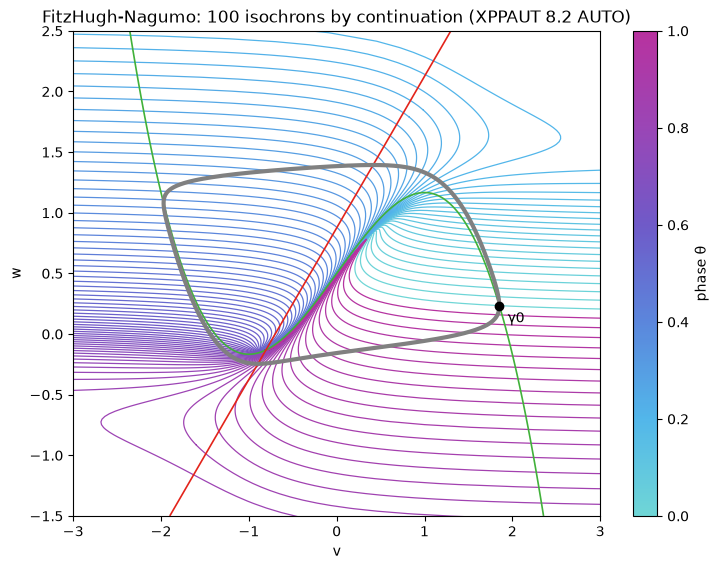

In [10]:
from matplotlib.colors import LinearSegmentedColormap
PHASE = LinearSegmentedColormap.from_list("cyan_magenta", ["#6fd6d6", "#52b6ea", "#5b86dc", "#6f5ac8", "#9a46b6", "#b8329f"])
fig, ax = plt.subplots(figsize=(8.5, 6.3))
for th, r in ISO.items():
    for key, u in r.items():
        ax.plot(u[:, 0], u[:, 1], color=PHASE(th), lw=0.9)
V, W = np.meshgrid(np.linspace(*WINDOW[:2], 400), np.linspace(*WINDOW[2:], 300))
ax.contour(V, W, V - V ** 3 / 3 - W + PARS["i"], [0], colors="#41b13a", linewidths=1.2)
ax.contour(V, W, V + PARS["a"] - PARS["b"] * W, [0], colors="#e3241b", linewidths=1.2)
ax.plot(POLY[:, 0], POLY[:, 1], color="0.5", lw=3)
ax.plot(*gamma0, "ko"); ax.annotate("γ0", gamma0, xytext=(6, -12), textcoords="offset points")
sm = plt.cm.ScalarMappable(cmap=PHASE, norm=plt.Normalize(0, 1))
fig.colorbar(sm, ax=ax, label="phase θ")
ax.set(xlim=WINDOW[:2], ylim=WINDOW[2:], xlabel="v", ylabel="w",
       title="FitzHugh-Nagumo: 100 isochrons by continuation (XPPAUT 8.2 AUTO)")
plt.show()

## 7. Checks

**Against brute force.** Take points of the computed isochrons, measure their asymptotic
phase directly from spike times (the method of notebook 01: a network of copies in one
XPP run), and compare with the phase θ_i of the isochron they belong to.

1000 isochron points tested; 697 are in the sensitive set (near x* and along the middle branch)
well-conditioned points (303): |brute-force phase − θ_i| median 1.8e-07, 99% 3.8e-07, max 3.8e-07


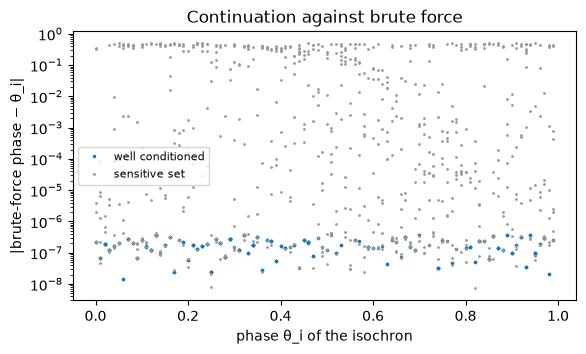

In [11]:
NC = 200
net = (ModelBuilder("fhn_net").ode(f"v[0..{NC - 1}]", "v[j]-v[j]^3/3-w[j]+i")
       .ode(f"w[0..{NC - 1}]", "eps*(v[j]+a-b*w[j])").parameter(**PARS)
       .option(dt=0.005, meth="rk4", bound=1e6, maxstor=400000).load(WORK / "fhn_net.ode"))
m.set(v=gamma0[0], w=gamma0[1])
r = m.run(keep=False, total=3 * T, dt=0.001)
vv = np.asarray(r["v"]); tt = np.asarray(r.t)
i0 = np.nonzero((vv[:-1] < 0) & (vv[1:] >= 0))[0][0]
tc0 = tt[i0] - vv[i0] / (vv[i0 + 1] - vv[i0]) * (tt[i0 + 1] - tt[i0])


def brute_phase(pts, nper=10):
    out = np.full(len(pts), np.nan)
    for s0 in range(0, len(pts), NC):
        chunk = pts[s0:s0 + NC]
        ic = {}
        for j in range(NC):
            p = chunk[j] if j < len(chunk) else chunk[0]
            ic[f"v{j}"], ic[f"w{j}"] = p[0], p[1]
        net.ics.update(ic)
        Ar = net.run(total=nper * T, trans=(nper - 2.5) * T).array
        t, Vv = Ar[:, 0], Ar[:, 1:1 + len(chunk)]
        for c in range(len(chunk)):
            i = np.nonzero((Vv[:-1, c] < 0) & (Vv[1:, c] >= 0))[0]
            if len(i) >= 2:
                ts = t[i] - Vv[i, c] / (Vv[i + 1, c] - Vv[i, c]) * (t[i + 1] - t[i])
                if abs(ts[-1] - ts[-2] - T) < 1e-3 * T:
                    out[s0 + c] = ((tc0 - ts[-1]) / T) % 1
    return out


def sensitivity(pts, dx=1e-6):
    """largest change of the brute-force phase when a point is moved by dx in v or w: above
    1e-3, the point is in the sensitive set and its phase cannot be pinned down at the
    accuracy of the computed points"""
    th = brute_phase(pts)
    s = np.zeros(len(pts))
    for mv in ((dx, 0), (-dx, 0), (0, dx), (0, -dx)):
        s = np.fmax(s, np.abs((brute_phase(pts + np.array(mv)) - th + 0.5) % 1 - 0.5))
    return th, s


rng = np.random.default_rng(1)
sample, phase_of_iso = [], []
for th, r_ in ISO.items():
    allp = np.vstack(list(r_.values()))[:, :2]
    inwin = allp[(allp[:, 0] > WINDOW[0]) & (allp[:, 0] < WINDOW[1]) & (allp[:, 1] > WINDOW[2]) & (allp[:, 1] < WINDOW[3])]
    pick = inwin[rng.choice(len(inwin), size=min(10, len(inwin)), replace=False)]
    sample.append(pick); phase_of_iso += [th] * len(pick)
sample = np.vstack(sample); phase_of_iso = np.array(phase_of_iso)
bf, sens = sensitivity(sample)
dev = (bf - phase_of_iso + 0.5) % 1 - 0.5
good = ~np.isnan(dev) & (sens < 1e-3)
print(f"{len(sample)} isochron points tested; {(sens >= 1e-3).sum()} are in the sensitive set "
      f"(near x* and along the middle branch)")
print(f"well-conditioned points ({good.sum()}): |brute-force phase − θ_i| median {np.median(np.abs(dev[good])):.1e}, "
      f"99% {np.percentile(np.abs(dev[good]), 99):.1e}, max {np.abs(dev[good]).max():.1e}")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.semilogy(phase_of_iso[good], np.abs(dev[good]) + 1e-12, ".", ms=3, label="well conditioned")
ax.semilogy(phase_of_iso[~good], np.abs(dev[~good]) + 1e-12, ".", ms=2, color="0.6", label="sensitive set")
ax.set(xlabel="phase θ_i of the isochron", ylabel="|brute-force phase − θ_i|",
       title="Continuation against brute force")
ax.legend(fontsize=8)
plt.show()

**No crossings.** Two isochrons of different phases cannot meet. Lines drawn through the
computed points of neighbouring isochrons (θ_i and θ_{i+1}) do appear to cross, but only
inside Γ, near x* and along the middle branch, where neighbouring isochrons are
exponentially close. A random sample of these apparent crossings is tested: if every end
point is in the sensitive set, the "crossing" is below the accuracy of the points; a
crossing between well-conditioned points would be a real error.

In [12]:
def orient(p, q, r):
    return np.sign((q[..., 0] - p[..., 0]) * (r[..., 1] - p[..., 1]) - (q[..., 1] - p[..., 1]) * (r[..., 0] - p[..., 0]))


def crossings(P, Q):
    """the crossing segment pairs of the polylines P and Q, as (P[i], P[i+1], Q[j], Q[j+1])"""
    a0, a1 = P[:-1, None], P[1:, None]
    b0, b1 = Q[None, :-1], Q[None, 1:]
    ia, ib = np.nonzero((orient(a0, a1, b0) * orient(a0, a1, b1) < 0) & (orient(b0, b1, a0) * orient(b0, b1, a1) < 0))
    return np.stack([P[ia], P[ia + 1], Q[ib], Q[ib + 1]], axis=1)


found = []
for i, th in enumerate(THETAS):
    th2 = THETAS[(i + 1) % NPHASE]
    for side in ("in", "out"):
        P = np.vstack([ISO[th][k][:, :2] for k in sorted(ISO[th]) if k.startswith(side)])[::2]
        Q = np.vstack([ISO[th2][k][:, :2] for k in sorted(ISO[th2]) if k.startswith(side)])[::2]
        c = crossings(P, Q)
        if len(c):
            found.append(c)
found = np.vstack(found) if found else np.zeros((0, 4, 2))
n_out = 0
print(f"apparent crossings between neighbouring isochrons: {len(found)}")
if len(found):
    mid = found.mean(axis=1)
    inside = Polygon(POLY).contains_points(mid)
    print(f"  inside Γ: {inside.sum()}, outside Γ: {(~inside).sum()}; "
          f"within 0.2 of x*: {(np.hypot(*(mid - xstar).T) < 0.2).sum()}")
    sel = found[rng.choice(len(found), size=min(1000, len(found)), replace=False)]
    _, s_end = sensitivity(sel.reshape(-1, 2))
    all_sensitive = (s_end.reshape(-1, 4) >= 1e-3).all(axis=1)
    n_bad = int((~all_sensitive).sum())
    print(f"  of {len(sel)} sampled crossings, {all_sensitive.sum()} have all four end points in the "
          f"sensitive set; {n_bad} involve a well-conditioned point")

apparent crossings between neighbouring isochrons: 117739


  inside Γ: 117739, outside Γ: 0; within 0.2 of x*: 80736


  of 1000 sampled crossings, 996 have all four end points in the sensitive set; 4 involve a well-conditioned point


## What we see

* Every isochron crosses Γ once, at its phase point, and has a branch outside and a
  branch inside Γ. The inside branches climb along the middle branch of the cubic
  v-nullcline, turn, and come back to the unstable equilibrium x*, the phaseless set,
  just as the reduced Hodgkin-Huxley isochrons do on a larger scale (compare the paper's
  Figure 2 and notebook 01's phase map).
* The contraction per period is μ ≈ 2 × 10⁻¹⁷, so most of each isochron is reached
  only through stages k ≥ 2, from segments that the BVP solver finds and backward
  integration cannot.
* **Checks.** Where the phase is well conditioned, the continuation points agree with
  the brute-force asymptotic phase to better than 10⁻⁶. About two thirds of the sampled
  points lie in the sensitive set, near x* and along the middle branch, where moving a
  point by 10⁻⁶ changes its phase by more than 10⁻³. The lines drawn between
  neighbouring isochrons appear to cross only there (none outside Γ). The handful of
  sampled crossings with a "well-conditioned" end point sit at the edge of that set (a
  10⁻⁶ move changes their phase by 0.7–1.3 × 10⁻³) and have chords about 10⁻² long,
  longer than the gap between the isochrons there: they are crossings of the drawn
  chords, not of the isochrons.
* The method is exactly the paper's: the same BVP, the same stages and concatenation, the
  same η and AUTO settings; only the vector field changed.